# Isothermal front speed: high temperature (10–100 MeV)

Numerical `solve_front_isothermal_slow(initial_guess_mode="auto")` and analytical `analytic_velocity_isothermal_slow` on a polar mesh. The rays start at $n_B=n_0$, $T=0$, and the points lie strictly between the two static boundaries:
- **Lower gray region:** pure neutron matter is stable against $\mu_K=0$ uds quark matter at the same $P,T$, so the speed is zero.
- **Upper gray region:** neutron matter converts directly to udd quark matter ($a(0^+)=1$), so the speed diverges.

No point inside a gray region is evaluated. The analytical speed is $v=c\sqrt{2I_2/[\lambda_n^2(1-a)(1+\xi a)]}$ with $I_2$, $\lambda_n$ and $a$ saved per point, so the comparison cell retunes $\xi$ instantly without new solves.
The band below 10 MeV comes from the low-temperature phase. Workflow: `new_paper_calculations/26-10-27/isothermal/`.

In [1]:
from pathlib import Path
import sys
import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt

ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "RMFsolver/phase_velocity.py").is_file())
WORKFLOW = ROOT / "new_paper_calculations/26-10-27/isothermal"
SCIPY_RUNTIME = ROOT / "local_analysis_results/26-10-02/runtime/scipy-1.18.1-cpython-312-darwin-arm64"
if "scipy" not in sys.modules and SCIPY_RUNTIME.is_dir():
    sys.path.insert(0, str(SCIPY_RUNTIME))   # the venv SciPy wheel does not load on macOS 27
sys.path[:0] = [str(WORKFLOW), str(WORKFLOW / "highT")]
import _iso_common as iso_common
import _iso_plot as iso_plot
import _iso_xi as iso_xi
import build_boundary_curves

numerical_highT = iso_common.load(WORKFLOW / "highT/isothermal-highT-numerical.npy")
analytic_highT = iso_common.load(WORKFLOW / "highT/isothermal-highT-analytic.npy")
assert numerical_highT["mesh"]["fingerprint"] == analytic_highT["mesh"]["fingerprint"]
assert numerical_highT["identity"]["sources"] == analytic_highT["identity"]["sources"]
boundary_curves = build_boundary_curves.load(numerical_highT["mesh"]["boundaries"])
xi_cache_highT = iso_xi.build_cache(analytic_highT)
for name, payload in (("numerical", numerical_highT), ("analytic", analytic_highT)):
    statuses = payload["status"].astype(str)
    counts = {s: int(np.sum(statuses == s)) for s in np.unique(statuses)}
    print(f"{name}: {counts}")
for level, entry in iso_plot.coverage(numerical_highT, iso_common.LEVELS_HIGH).items():
    missing = {}
    for reason in entry["missing"].values():
        missing[reason] = missing.get(reason, 0) + 1
    print(f"  numerical {level:6g} m/s: bracketed on {len(entry['bracketed'])} rays; missing {missing}")

# Low-temperature row mesh (0.01-10 MeV), drawn below 10 MeV when present.
low_T_paths = {m: WORKFLOW / f"lowT/isothermal-lowT-{m}.npy" for m in ("numerical", "analytic")}
numerical_lowT, analytic_lowT = (iso_common.load(p) if p.is_file() else None for p in low_T_paths.values())
xi_cache_lowT = iso_xi.build_cache(analytic_lowT) if analytic_lowT is not None else None
for name, payload in (("numerical low T", numerical_lowT), ("analytic low T", analytic_lowT)):
    if payload is not None:
        statuses = payload["status"].astype(str)
        print(f"{name}: { {s: int(np.sum(statuses == s)) for s in np.unique(statuses)} }")

numerical: {np.str_('accepted'): 2282, np.str_('outside_panel'): 58, np.str_('unresolved'): 9}
analytic: {np.str_('accepted'): 2291, np.str_('outside_panel'): 58}
  numerical     50 m/s: bracketed on 77 rays; missing {'masked': 1, 'below_inner_column': 3}
  numerical    100 m/s: bracketed on 77 rays; missing {'masked': 1, 'below_inner_column': 3}
  numerical    200 m/s: bracketed on 78 rays; missing {'masked': 1, 'below_inner_column': 2}
  numerical    500 m/s: bracketed on 79 rays; missing {'masked': 1, 'below_inner_column': 1}
  numerical   1000 m/s: bracketed on 79 rays; missing {'masked': 1, 'below_inner_column': 1}
  numerical   2000 m/s: bracketed on 80 rays; missing {'masked': 1}
  numerical   5000 m/s: bracketed on 80 rays; missing {'masked': 1}
numerical low T: {np.str_('accepted'): 1314, np.str_('timeout'): 36, np.str_('unresolved'): 50}
analytic low T: {np.str_('accepted'): 1400}


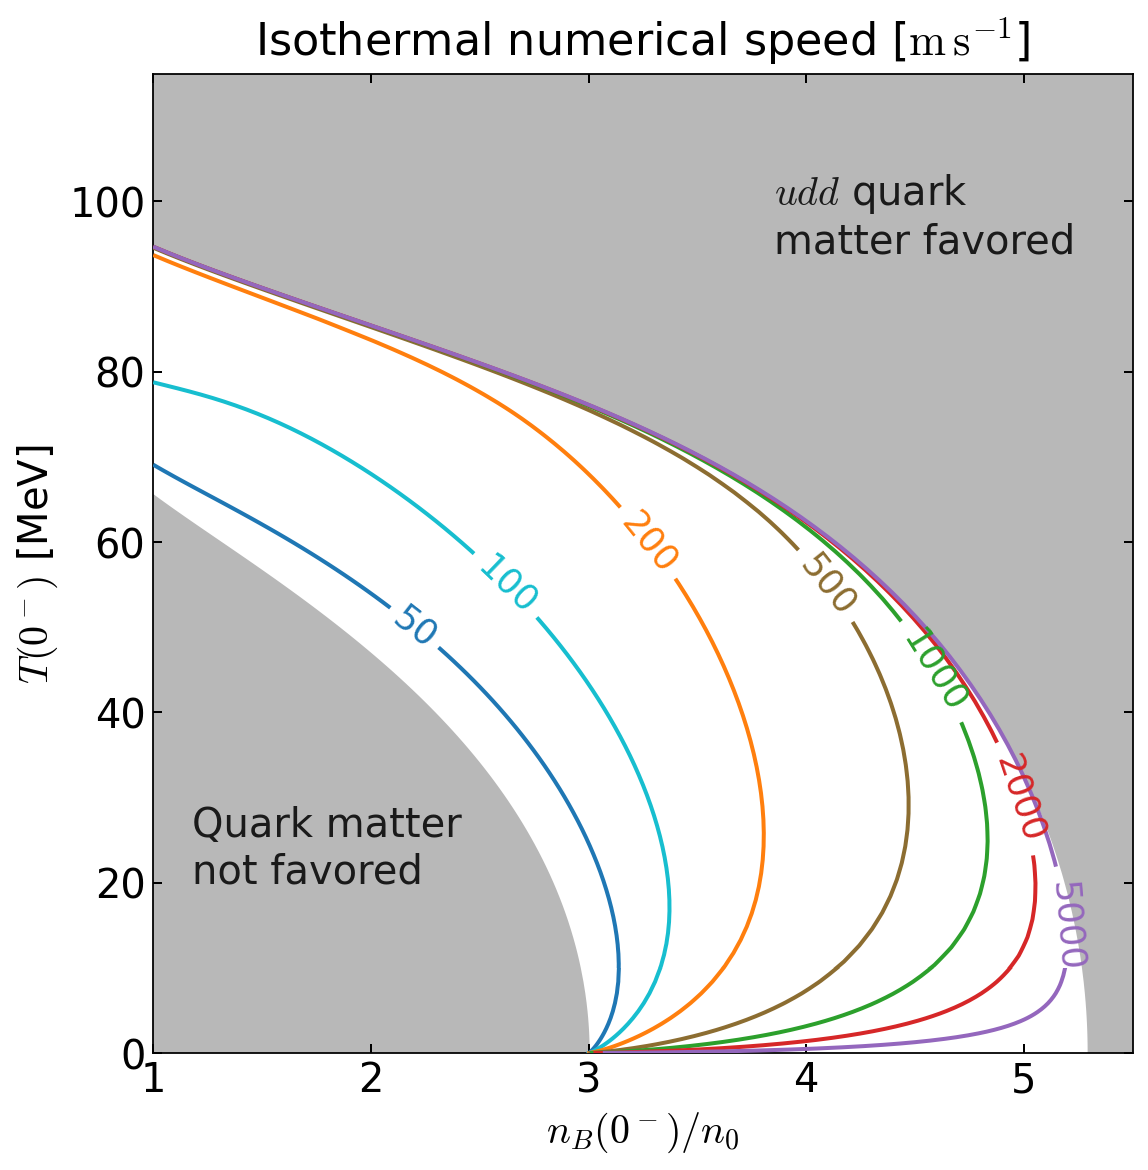

In [2]:
# Tunable plotting parameters
VELOCITY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0)
VELOCITY_CONTOUR_COLORS = ('#1f77b4', '#17becf', '#ff7f0e', '#8c6d31', '#2ca02c', '#d62728', '#9467bd')
VELOCITY_CONTOUR_LINE_STYLE = '-'
VELOCITY_CONTOUR_LINE_WIDTH = 1.8
CONTOUR_LABEL_FONT_SIZE = 16
CONTOUR_LABEL_FORMAT = '%g'
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
CONTOUR_LABEL_TEMPERATURES_MEV = {50.0: 50.0, 100.0: 55.0, 200.0: 60.0, 500.0: 55.0, 1000.0: 45.0, 2000.0: 30.0, 5000.0: 15.0}
CONTOUR_ZORDER = 3
EXCLUDED_REGION_COLOR = '0.72'
EXCLUDED_REGION_ALPHA = 1.0
EXCLUDED_REGION_ZORDER = 0
OUTER_REGION_TEXT = '$udd$ quark\nmatter favored'
OUTER_REGION_TEXT_POSITION = (3.85, 94.0)
INNER_REGION_TEXT = 'Quark matter\nnot favored'
INNER_REGION_TEXT_POSITION = (1.18, 20.0)
REGION_TEXT_COLOR = '0.10'
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 5
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
BACKGROUND_COLOR = 'white'
CONSTRAINED_LAYOUT = True
MATHTEXT_FONTSET = 'cm'
MATHTEXT_ROMAN = 'serif'
MATHTEXT_ITALIC = 'serif:italic'
MATHTEXT_BOLD = 'serif:bold'
X_LIMITS = (1.0, 5.5)
Y_LIMITS_MEV = (0.0, 115.0)
X_SCALE = 'linear'
Y_SCALE = 'linear'
BOX_ASPECT = 1.0
TITLE = 'Isothermal numerical speed [$\\mathrm{m\\,s^{-1}}$]'
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
X_LABEL = '$n_B(0^-)/n_0$'
Y_LABEL = '$T(0^-)$ [MeV]'
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = 'in'
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
HIGH_T_CLIP_MEV = 10.0   # polar mesh above, row mesh below
RADIAL_UPSAMPLE = 8   # display-only PCHIP refinement along rays in -ln(1-f)
LOW_T_UPSAMPLE = 8    # display-only PCHIP refinement along rows in logit(f)
OUTPUT_STEM = "local_analysis_results/26-10-27/isothermal-numerical-linear"

style = dict(iso_plot.LINEAR_REFERENCE_STYLE)
style.update({key.lower(): value for key, value in list(globals().items())
              if key.isupper() and key.lower() in style})

figure, axis, rc = iso_plot.new_axes(style)
with mpl.rc_context(rc):
    iso_plot.draw_background(axis, boundary_curves, style)
    iso_plot.draw_contours(axis, numerical_highT, T_range=(HIGH_T_CLIP_MEV, np.inf), style=style,
                           radial_upsample=RADIAL_UPSAMPLE)
    if numerical_lowT is not None:
        iso_plot.draw_row_contours(axis, numerical_lowT, VELOCITY_CONTOUR_LEVELS_M_S, VELOCITY_CONTOUR_COLORS,
                                   VELOCITY_CONTOUR_LINE_STYLE, VELOCITY_CONTOUR_LINE_WIDTH, CONTOUR_ZORDER,
                                   T_range=(Y_LIMITS_MEV[0], HIGH_T_CLIP_MEV), x_limits=X_LIMITS,
                                   radial_upsample=LOW_T_UPSAMPLE)
    iso_plot.finish_axes(axis, style)
    iso_plot.export(figure, ROOT / OUTPUT_STEM, style)
    plt.show()

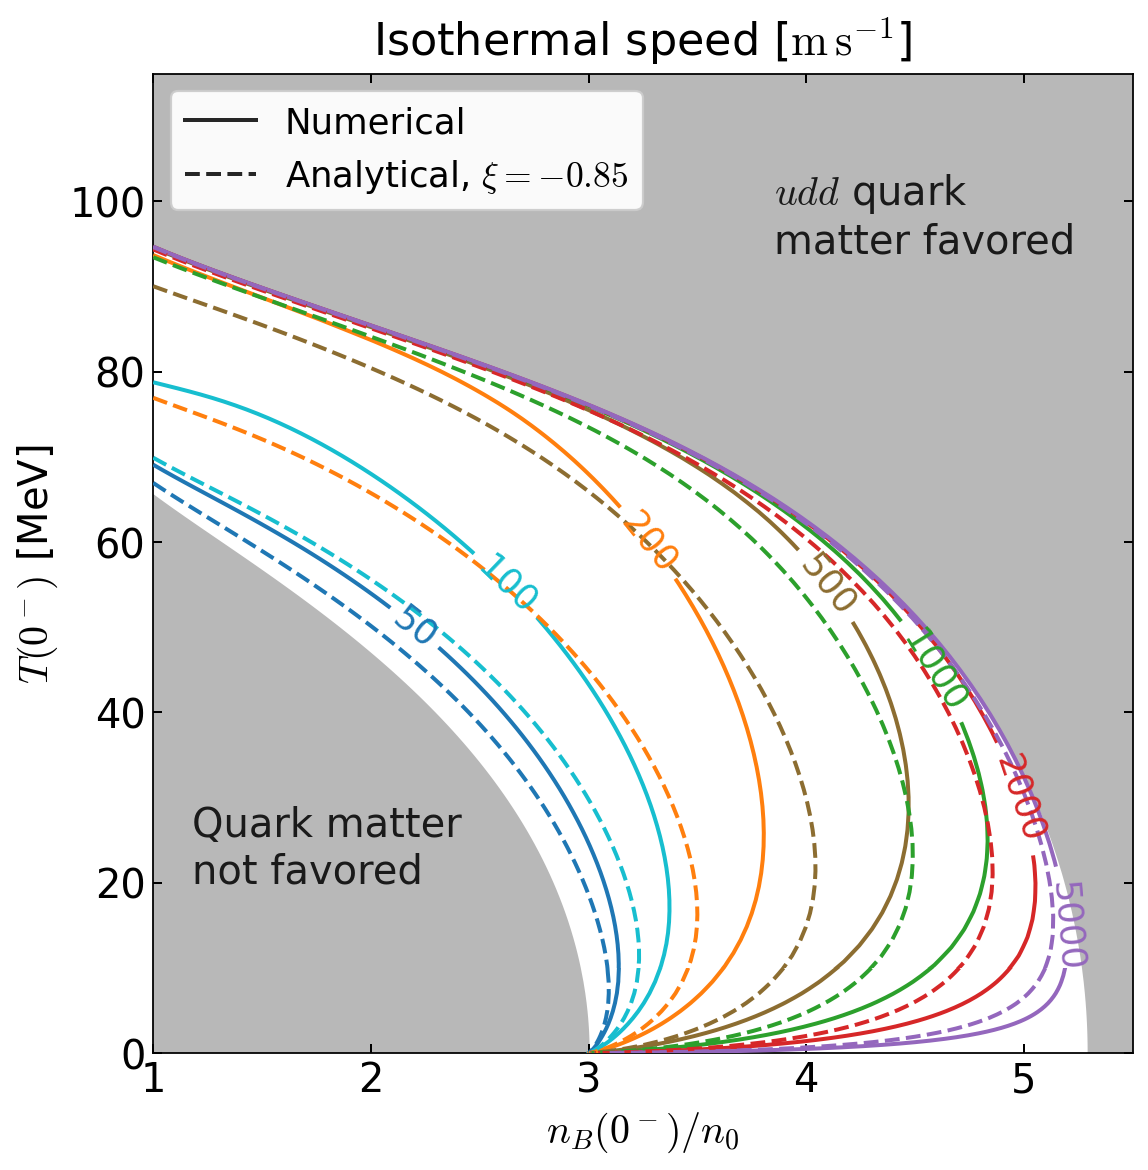

In [3]:
# Tunable plotting parameters
VELOCITY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0)
VELOCITY_CONTOUR_COLORS = ('#1f77b4', '#17becf', '#ff7f0e', '#8c6d31', '#2ca02c', '#d62728', '#9467bd')
VELOCITY_CONTOUR_LINE_STYLE = '-'
VELOCITY_CONTOUR_LINE_WIDTH = 1.8
CONTOUR_LABEL_FONT_SIZE = 16
CONTOUR_LABEL_FORMAT = '%g'
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
CONTOUR_LABEL_TEMPERATURES_MEV = {50.0: 50.0, 100.0: 55.0, 200.0: 60.0, 500.0: 55.0, 1000.0: 45.0, 2000.0: 30.0, 5000.0: 15.0}
CONTOUR_ZORDER = 3
EXCLUDED_REGION_COLOR = '0.72'
EXCLUDED_REGION_ALPHA = 1.0
EXCLUDED_REGION_ZORDER = 0
OUTER_REGION_TEXT = '$udd$ quark\nmatter favored'
OUTER_REGION_TEXT_POSITION = (3.85, 94.0)
INNER_REGION_TEXT = 'Quark matter\nnot favored'
INNER_REGION_TEXT_POSITION = (1.18, 20.0)
REGION_TEXT_COLOR = '0.10'
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 5
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
BACKGROUND_COLOR = 'white'
CONSTRAINED_LAYOUT = True
MATHTEXT_FONTSET = 'cm'
MATHTEXT_ROMAN = 'serif'
MATHTEXT_ITALIC = 'serif:italic'
MATHTEXT_BOLD = 'serif:bold'
X_LIMITS = (1.0, 5.5)
Y_LIMITS_MEV = (0.0, 115.0)
X_SCALE = 'linear'
Y_SCALE = 'linear'
BOX_ASPECT = 1.0
TITLE = 'Isothermal numerical speed [$\\mathrm{m\\,s^{-1}}$]'
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
X_LABEL = '$n_B(0^-)/n_0$'
Y_LABEL = '$T(0^-)$ [MeV]'
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = 'in'
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
XI = -0.85
HIGH_T_CLIP_MEV = 10.0
RADIAL_UPSAMPLE = 8   # display-only PCHIP refinement along rays in -ln(1-f)
TITLE = 'Isothermal speed [$\\mathrm{m\\,s^{-1}}$]'
ANALYTICAL_LINE_STYLE = '--'
NUMERICAL_LINE_STYLE = '-'
LEGEND_LOCATION = 'upper left'
LEGEND_FONT_SIZE = 16
LEGEND_HANDLE_COLOR = '0.15'
LOW_T_UPSAMPLE = 8    # display-only PCHIP refinement along rows in logit(f)
OUTPUT_STEM = "local_analysis_results/26-10-27/isothermal-comparison-linear"

style = dict(iso_plot.LINEAR_REFERENCE_STYLE)
style.update({key.lower(): value for key, value in list(globals().items())
              if key.isupper() and key.lower() in style})
analytic_retuned = dict(analytic_highT, speed_m_s=iso_xi.retune(xi_cache_highT, XI))

figure, axis, rc = iso_plot.new_axes(style)
with mpl.rc_context(rc):
    iso_plot.draw_background(axis, boundary_curves, style)
    iso_plot.draw_contours(axis, numerical_highT, T_range=(HIGH_T_CLIP_MEV, np.inf), style=style,
                           line_style=NUMERICAL_LINE_STYLE, radial_upsample=RADIAL_UPSAMPLE)
    iso_plot.draw_contours(axis, analytic_retuned, T_range=(HIGH_T_CLIP_MEV, np.inf), style=style,
                           line_style=ANALYTICAL_LINE_STYLE, label=False,
                           radial_upsample=RADIAL_UPSAMPLE)
    if numerical_lowT is not None:
        analytic_lowT_retuned = dict(analytic_lowT, speed_m_s=iso_xi.retune(xi_cache_lowT, XI))
        for payload, line_style in ((numerical_lowT, NUMERICAL_LINE_STYLE), (analytic_lowT_retuned, ANALYTICAL_LINE_STYLE)):
            iso_plot.draw_row_contours(axis, payload, VELOCITY_CONTOUR_LEVELS_M_S, VELOCITY_CONTOUR_COLORS,
                                       line_style, VELOCITY_CONTOUR_LINE_WIDTH, CONTOUR_ZORDER,
                                       T_range=(Y_LIMITS_MEV[0], HIGH_T_CLIP_MEV), x_limits=X_LIMITS,
                                       radial_upsample=LOW_T_UPSAMPLE)
    iso_plot.method_legend(axis, [("Numerical", NUMERICAL_LINE_STYLE),
                                  (rf"Analytical, $\xi={XI:g}$", ANALYTICAL_LINE_STYLE)],
                           font_size=LEGEND_FONT_SIZE, location=LEGEND_LOCATION, color=LEGEND_HANDLE_COLOR,
                           line_width=VELOCITY_CONTOUR_LINE_WIDTH)
    iso_plot.finish_axes(axis, style, title=TITLE)
    iso_plot.export(figure, ROOT / OUTPUT_STEM, style)
    plt.show()

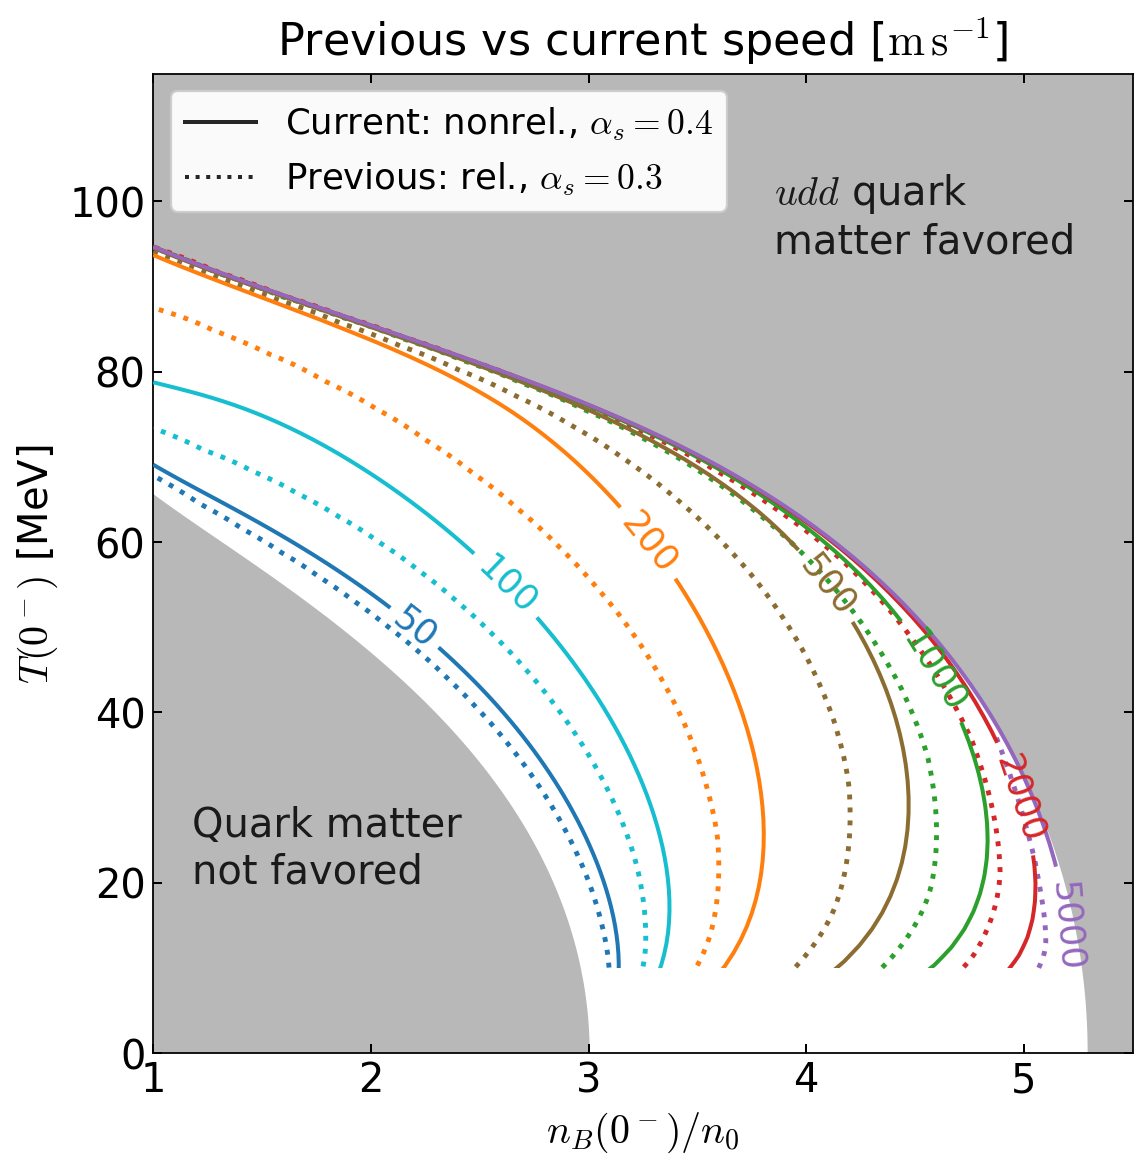

In [4]:
# Tunable plotting parameters
VELOCITY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0)
VELOCITY_CONTOUR_COLORS = ('#1f77b4', '#17becf', '#ff7f0e', '#8c6d31', '#2ca02c', '#d62728', '#9467bd')
VELOCITY_CONTOUR_LINE_STYLE = '-'
VELOCITY_CONTOUR_LINE_WIDTH = 1.8
CONTOUR_LABEL_FONT_SIZE = 16
CONTOUR_LABEL_FORMAT = '%g'
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
CONTOUR_LABEL_TEMPERATURES_MEV = {50.0: 50.0, 100.0: 55.0, 200.0: 60.0, 500.0: 55.0, 1000.0: 45.0, 2000.0: 30.0, 5000.0: 15.0}
CONTOUR_ZORDER = 3
EXCLUDED_REGION_COLOR = '0.72'
EXCLUDED_REGION_ALPHA = 1.0
EXCLUDED_REGION_ZORDER = 0
OUTER_REGION_TEXT = '$udd$ quark\nmatter favored'
OUTER_REGION_TEXT_POSITION = (3.85, 94.0)
INNER_REGION_TEXT = 'Quark matter\nnot favored'
INNER_REGION_TEXT_POSITION = (1.18, 20.0)
REGION_TEXT_COLOR = '0.10'
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 5
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
BACKGROUND_COLOR = 'white'
CONSTRAINED_LAYOUT = True
MATHTEXT_FONTSET = 'cm'
MATHTEXT_ROMAN = 'serif'
MATHTEXT_ITALIC = 'serif:italic'
MATHTEXT_BOLD = 'serif:bold'
X_LIMITS = (1.0, 5.5)
Y_LIMITS_MEV = (0.0, 115.0)
X_SCALE = 'linear'
Y_SCALE = 'linear'
BOX_ASPECT = 1.0
TITLE = 'Isothermal numerical speed [$\\mathrm{m\\,s^{-1}}$]'
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
X_LABEL = '$n_B(0^-)/n_0$'
Y_LABEL = '$T(0^-)$ [MeV]'
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = 'in'
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
HIGH_T_CLIP_MEV = 10.0
RADIAL_UPSAMPLE = 8   # display-only PCHIP refinement along rays in -ln(1-f)
TITLE = 'Previous vs current speed [$\\mathrm{m\\,s^{-1}}$]'
PREVIOUS_LINE_STYLE = ':'
PREVIOUS_LINE_WIDTH = 2.2
PREVIOUS_ARCHIVE = "local_analysis_results/All_Plots_new/isothermal_contour_data/isothermal-numerical-contour.npz"
LEGEND_LOCATION = 'upper left'
LEGEND_FONT_SIZE = 16
LEGEND_HANDLE_COLOR = '0.15'
OUTPUT_STEM = "local_analysis_results/26-10-27/isothermal-highT-old-vs-new"

style = dict(iso_plot.LINEAR_REFERENCE_STYLE)
style.update({key.lower(): value for key, value in list(globals().items())
              if key.isupper() and key.lower() in style})
previous = np.load(ROOT / PREVIOUS_ARCHIVE)
previous_levels = previous["levels_m_s"].tolist()

figure, axis, rc = iso_plot.new_axes(style)
with mpl.rc_context(rc):
    iso_plot.draw_background(axis, boundary_curves, style)
    for level, color in zip(VELOCITY_CONTOUR_LEVELS_M_S, VELOCITY_CONTOUR_COLORS):
        curve = previous[f"curve_vertices_{previous_levels.index(level)}"]
        curve = curve[curve[:, 1] >= HIGH_T_CLIP_MEV]
        axis.plot(curve[:, 0], curve[:, 1], PREVIOUS_LINE_STYLE, color=color,
                  linewidth=PREVIOUS_LINE_WIDTH, zorder=CONTOUR_ZORDER)
    iso_plot.draw_contours(axis, numerical_highT, T_range=(HIGH_T_CLIP_MEV, np.inf), style=style,
                           radial_upsample=RADIAL_UPSAMPLE)
    iso_plot.method_legend(axis, [("Current: nonrel., $\\alpha_s=0.4$", "-"),
                                  ("Previous: rel., $\\alpha_s=0.3$", PREVIOUS_LINE_STYLE)],
                           font_size=LEGEND_FONT_SIZE, location=LEGEND_LOCATION, color=LEGEND_HANDLE_COLOR)
    iso_plot.finish_axes(axis, style, title=TITLE)
    iso_plot.export(figure, ROOT / OUTPUT_STEM, style)
    plt.show()

## Low temperature (0.01–10 MeV), logarithmic axis

Row mesh: on each of the 40 logarithmic rows, $n_B=x_{\rm in}(T)+f\,[x_{\rm out}(T)-x_{\rm in}(T)]$ strictly between that row's coexistence and udd roots, with $f$ from $10^{-5}$ to $1-10^{-4}$. Contours are computed in $(n_B,\log_{10}T)$, numerical solid and analytical dashed. The styling follows `26-10-02.ipynb` cell 8; the upper limit is now 10 MeV.

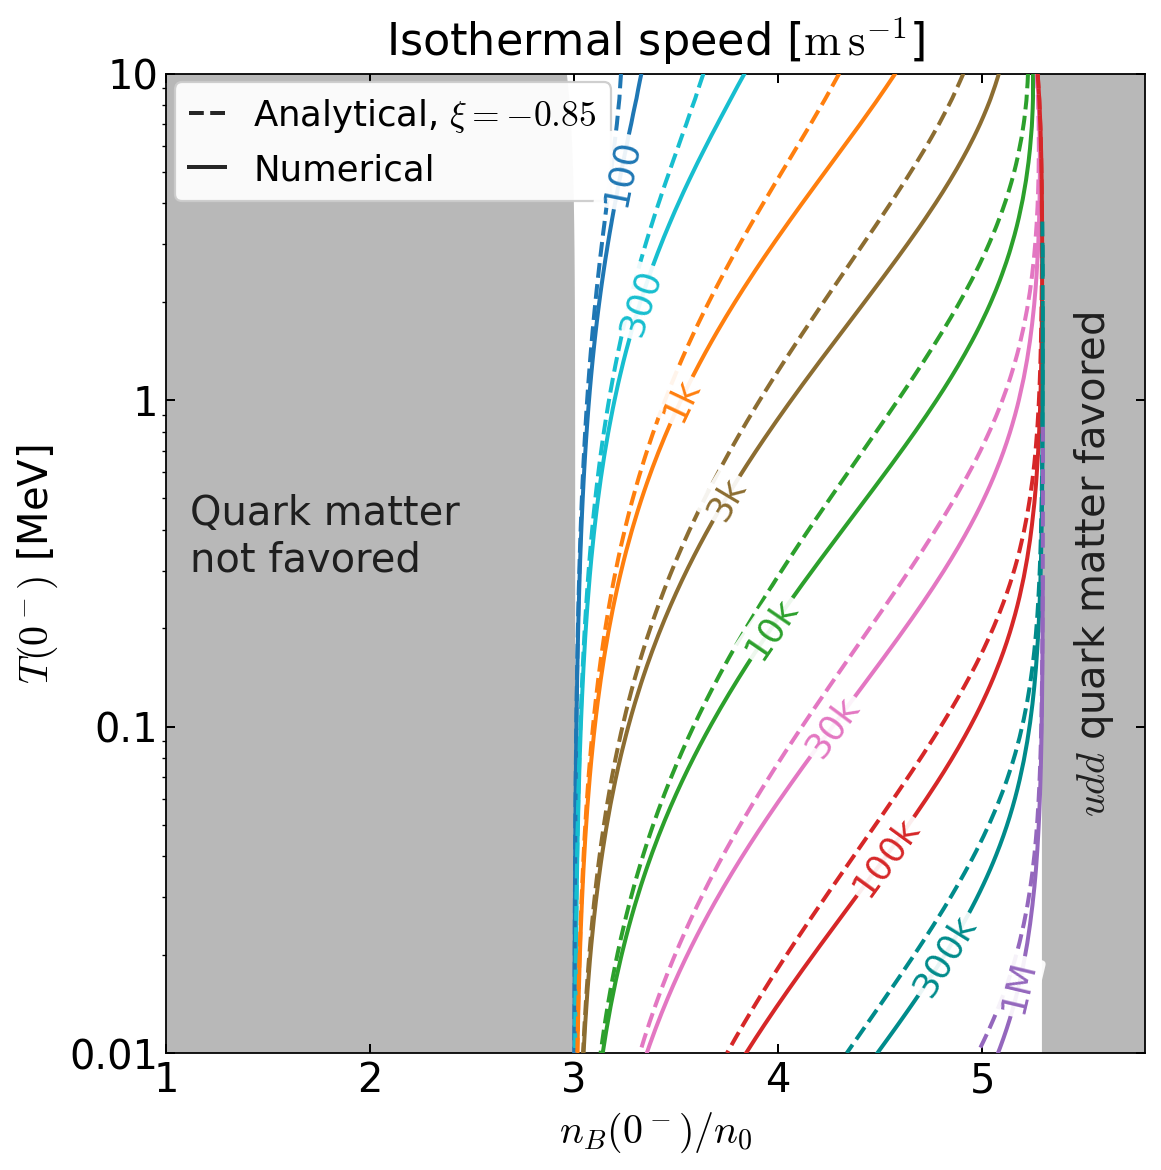

In [5]:
# Tunable plotting parameters
CONTOUR_LEVELS = (100.0, 300.0, 1000.0, 3000.0, 10000.0, 30000.0, 100000.0, 300000.0, 1000000.0)
CONTOUR_COLORS = ('#1f77b4', '#17becf', '#ff7f0e', '#8c6d31', '#2ca02c', '#e377c2', '#d62728', '#008b8b', '#9467bd')
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
CONSTRAINED_LAYOUT = True
BACKGROUND_COLOR = 'white'
FONT_FAMILY = 'DejaVu Sans'
MATH_FONT_SET = 'cm'
USE_TEX = False
BOX_ASPECT = 1.0
X_LIMITS = (1.0, 5.8)
Y_LIMITS = (0.01, 10.0)
X_SCALE = 'linear'
Y_SCALE = 'log'
X_TICKS = (1.0, 2.0, 3.0, 4.0, 5.0)
Y_TICKS = (0.01, 0.1, 1.0, 10.0)
Y_TICK_LABELS = ('0.01', '0.1', '1', '10')
TITLE = 'Isothermal speed [$\\mathrm{m\\,s^{-1}}$]'
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
X_LABEL = '$n_B(0^-)/n_0$'
Y_LABEL = '$T(0^-)$ [MeV]'
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = 'in'
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
ANALYTICAL_LINE_STYLE = '--'
NUMERICAL_LINE_STYLE = '-'
LINE_WIDTH = 1.8
ANALYTICAL_ZORDER = 4
NUMERICAL_ZORDER = 3
NUMERICAL_SPLIT_TEMPERATURE = 20.0
NUMERICAL_MARKER = 'o'
MARKER_SIZE = 19.0
MARKER_EDGE_COLOR = 'white'
MARKER_EDGE_WIDTH = 0.35
MARKER_ALPHA = 1.0
MARKER_ZORDER = 5
ISOLATED_ANALYTICAL_MARKER = 'x'
ISOLATED_ANALYTICAL_SIZE = 15.0
LABEL_CURVES = True
CONTOUR_LABEL_FONT_SIZE = 16
CONTOUR_LABEL_FORMAT = '%g'
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
CONTOUR_LABEL_BACKGROUND_COLOR = 'white'
CONTOUR_LABEL_BACKGROUND_ALPHA = 0.92
CONTOUR_LABEL_BACKGROUND_PAD = 0.12
CONTOUR_LABEL_BACKGROUND_STYLE = 'round'
CONTOUR_LABEL_EDGE_COLOR = 'none'
CONTOUR_LABEL_ZORDER = 6
LABEL_TEMPERATURES = {100.0: 5.0, 300.0: 2.0, 1000.0: 1.0, 3000.0: 0.5, 10000.0: 0.2, 30000.0: 0.1, 100000.0: 0.04, 300000.0: 0.02, 1000000.0: 0.016}
EXCLUDED_REGION_COLOR = '0.72'
EXCLUDED_REGION_ALPHA = 1.0
EXCLUDED_REGION_ZORDER = 0
INNER_REGION_TEXT = 'Quark matter\nnot favored'
INNER_REGION_POSITION = (1.12, 0.3)
OUTER_REGION_TEXT = '$udd$ quark matter favored'
OUTER_REGION_POSITION = (5.55, 0.316)
OUTER_REGION_ROTATION = 90
OUTER_REGION_ALIGNMENT = 'center'
OUTER_REGION_VERTICAL_ALIGNMENT = 'center'
REGION_TEXT_COLOR = '0.12'
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 6
LEGEND_LOCATION = 'upper left'
LEGEND_FONT_SIZE = 16
LEGEND_HANDLE_LENGTH = 1.0
LEGEND_BORDER_AXES_PAD = 0.25
LEGEND_FRAME_ALPHA = 0.94
LEGEND_FACE_COLOR = 'white'
LEGEND_EDGE_COLOR = '0.8'
LEGEND_HANDLE_COLOR = '0.15'
LEGEND_MARKER_SIZE = 5.0
SHOW_METHOD_LEGEND = True
SHOW_SPEED_LEGEND = False
SPEED_LEGEND_LOCATION = 'lower left'
SPEED_LEGEND_TITLE = '$u(0^-)$ [m s$^{-1}$]'
SPEED_LEGEND_FONT_SIZE = 16
SPEED_LEGEND_COLUMNS = 2
SPEED_LEGEND_ANCHOR = (0.005, 0.005)
SPEED_LEGEND_HANDLE_LENGTH = 1.3
SPEED_LEGEND_COLUMN_SPACING = 0.7
SPEED_LEGEND_HANDLE_TEXT_PAD = 0.4
SPEED_LEGEND_LABEL_SPACING = 0.3
SPEED_LABELS = ('100', '300', '1k', '3k', '10k', '30k', '100k', '300k', '1M')
SHOW_GRID = False
EXPORT_STEM = 'isothermal-lowT-logT'
XI = -0.85
LOW_T_UPSAMPLE = 8    # display-only PCHIP refinement along rows in logit(f)
OUTPUT_DIRECTORY = "local_analysis_results/26-10-27"

log_style = dict(iso_plot.LOG_REFERENCE_STYLE)
log_style.update({key.lower(): value for key, value in list(globals().items())
                  if key.isupper() and key.lower() in log_style})
analytic_lowT_retuned = dict(analytic_lowT, speed_m_s=iso_xi.retune(xi_cache_lowT, XI))
lines = {}
for name, payload in (("numerical", numerical_lowT), ("analytic", analytic_lowT_retuned)):
    x, T, logv = iso_plot.contour_arrays(payload, LOW_T_UPSAMPLE, "logit")
    lines[name] = iso_plot.contour_lines(x, T, logv, CONTOUR_LEVELS, log_T=True)

with plt.rc_context({"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONT_SET, "text.usetex": USE_TEX}):
    figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI, constrained_layout=CONSTRAINED_LAYOUT,
                                facecolor=BACKGROUND_COLOR)
    axis.set_facecolor(BACKGROUND_COLOR)
    iso_plot.draw_log_reference(axis, boundary_curves, lines["numerical"], lines["analytic"], XI, log_style)
    for extension in ("png", "pdf"):
        figure.savefig(ROOT / OUTPUT_DIRECTORY / f"{EXPORT_STEM}.{extension}", dpi=EXPORT_DPI,
                       facecolor=BACKGROUND_COLOR)
    plt.show()

## Tuning $\xi$ to the numerical speeds

`xi_fit/fit_xi.py` rescales the saved analytical intermediates exactly, $u(0^-;\xi)=\sqrt{2I_2}/\big(\lambda_n\sqrt{[1-a(0^+)][1+\xi a(0^+)]}\big)$, with no solver calls. It fits one $\xi$ per panel by minimizing the RMS displacement of the plotted contours along rays (high $T$) or rows (low $T$), in units of $n_0$, as for the adiabatic fit. A log-speed fit over all points and a separate anchor fit for every contour level are reported alongside. Near coexistence $a(0^+)\to0$, so $\xi$ barely moves those contours.

In [6]:
import json

XI_FIT_FILE = WORKFLOW / "xi_fit/xi_fit.json"
xi_fit = json.loads(XI_FIT_FILE.read_text())
for name, fit in xi_fit["fits"].items():
    print(f"{name:6s} contour-fit xi = {fit['contour']['xi']:+.3f}   log-speed-fit xi = {fit['log_speed']['xi']:+.3f}")
for tag, levels in xi_fit["level_anchors"].items():
    print(f"{tag} level anchors: " + ", ".join(f"{k}: {v['xi']:+.2f}" for k, v in levels.items()))
for label, entry in xi_fit["at_candidates"].items():
    print(f"xi = {entry['xi']:+.3f} ({label})")
    for tag in ("highT", "lowT"):
        e = entry[tag]
        print(f"   {tag}: contour offset RMS {e['rms_offset_n0']:.3f} n0, max {e['max_abs_offset_n0']:.3f} n0; "
              "analytic/numerical speed p5/50/95 " + ", ".join(f"{r:.2f}" for r in e["speed_ratio_percentiles_5_50_95"]))
XI_HIGH_T_FIT = round(xi_fit["fits"]["highT"]["contour"]["xi"], 2)
XI_LOW_T_FIT = round(xi_fit["fits"]["lowT"]["contour"]["xi"], 2)

highT  contour-fit xi = +0.741   log-speed-fit xi = +0.940
lowT   contour-fit xi = -0.566   log-speed-fit xi = -0.695
both   contour-fit xi = +0.197   log-speed-fit xi = +0.212
highT level anchors: 50: +2.01, 100: +1.33, 200: +0.67, 500: +0.02, 1000: -0.27, 2000: -0.45, 5000: -0.60
lowT level anchors: 100: +0.51, 300: -0.03, 1000: -0.35, 3000: -0.50, 10000: -0.57, 30000: -0.60, 100000: -0.63, 300000: -0.67, 1e+06: -0.74
xi = -0.850 (reference)
   highT: contour offset RMS 0.288 n0, max 0.640 n0; analytic/numerical speed p5/50/95 1.41, 2.16, 5.61
   lowT: contour offset RMS 0.092 n0, max 0.274 n0; analytic/numerical speed p5/50/95 1.05, 1.22, 1.45
xi = +0.741 (highT_contour)
   highT: contour offset RMS 0.078 n0, max 0.340 n0; analytic/numerical speed p5/50/95 0.58, 1.13, 1.66
   lowT: contour offset RMS 0.174 n0, max 0.421 n0; analytic/numerical speed p5/50/95 0.34, 0.72, 1.11
xi = -0.566 (lowT_contour)
   highT: contour offset RMS 0.209 n0, max 0.520 n0; analytic/numerical speed p5/50

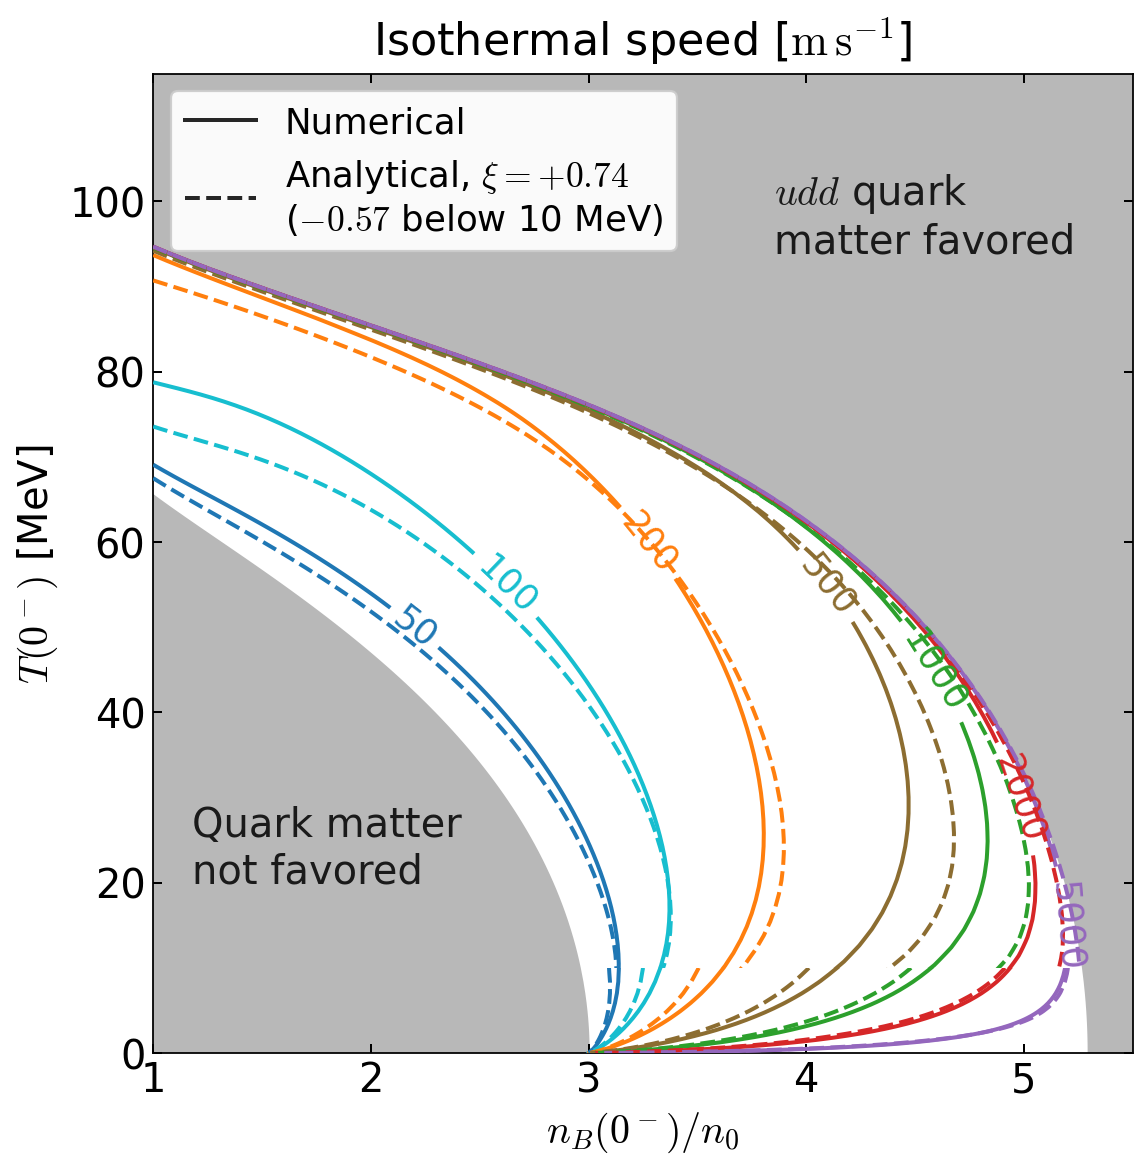

In [7]:
# Tunable plotting parameters
VELOCITY_CONTOUR_LEVELS_M_S = (50.0, 100.0, 200.0, 500.0, 1000.0, 2000.0, 5000.0)
VELOCITY_CONTOUR_COLORS = ('#1f77b4', '#17becf', '#ff7f0e', '#8c6d31', '#2ca02c', '#d62728', '#9467bd')
VELOCITY_CONTOUR_LINE_STYLE = '-'
VELOCITY_CONTOUR_LINE_WIDTH = 1.8
CONTOUR_LABEL_FONT_SIZE = 16
CONTOUR_LABEL_FORMAT = '%g'
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
CONTOUR_LABEL_TEMPERATURES_MEV = {50.0: 50.0, 100.0: 55.0, 200.0: 60.0, 500.0: 55.0, 1000.0: 45.0, 2000.0: 30.0, 5000.0: 15.0}
CONTOUR_ZORDER = 3
EXCLUDED_REGION_COLOR = '0.72'
EXCLUDED_REGION_ALPHA = 1.0
EXCLUDED_REGION_ZORDER = 0
OUTER_REGION_TEXT = '$udd$ quark\nmatter favored'
OUTER_REGION_TEXT_POSITION = (3.85, 94.0)
INNER_REGION_TEXT = 'Quark matter\nnot favored'
INNER_REGION_TEXT_POSITION = (1.18, 20.0)
REGION_TEXT_COLOR = '0.10'
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 5
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
BACKGROUND_COLOR = 'white'
CONSTRAINED_LAYOUT = True
MATHTEXT_FONTSET = 'cm'
MATHTEXT_ROMAN = 'serif'
MATHTEXT_ITALIC = 'serif:italic'
MATHTEXT_BOLD = 'serif:bold'
X_LIMITS = (1.0, 5.5)
Y_LIMITS_MEV = (0.0, 115.0)
X_SCALE = 'linear'
Y_SCALE = 'linear'
BOX_ASPECT = 1.0
TITLE = 'Isothermal numerical speed [$\\mathrm{m\\,s^{-1}}$]'
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
X_LABEL = '$n_B(0^-)/n_0$'
Y_LABEL = '$T(0^-)$ [MeV]'
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = 'in'
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
XI = XI_HIGH_T_FIT   # contour fit on the polar mesh (T >= 10 MeV)
XI_LOW_T = XI_LOW_T_FIT   # contour fit on the row mesh (T < 10 MeV)
HIGH_T_CLIP_MEV = 10.0
RADIAL_UPSAMPLE = 8   # display-only PCHIP refinement along rays in -ln(1-f)
TITLE = 'Isothermal speed [$\\mathrm{m\\,s^{-1}}$]'
ANALYTICAL_LINE_STYLE = '--'
NUMERICAL_LINE_STYLE = '-'
LEGEND_LOCATION = 'upper left'
LEGEND_FONT_SIZE = 16
LEGEND_HANDLE_COLOR = '0.15'
LOW_T_UPSAMPLE = 8    # display-only PCHIP refinement along rows in logit(f)
OUTPUT_STEM = "local_analysis_results/26-10-27/isothermal-comparison-linear-xi-fit"

style = dict(iso_plot.LINEAR_REFERENCE_STYLE)
style.update({key.lower(): value for key, value in list(globals().items())
              if key.isupper() and key.lower() in style})
analytic_retuned = dict(analytic_highT, speed_m_s=iso_xi.retune(xi_cache_highT, XI))

figure, axis, rc = iso_plot.new_axes(style)
with mpl.rc_context(rc):
    iso_plot.draw_background(axis, boundary_curves, style)
    iso_plot.draw_contours(axis, numerical_highT, T_range=(HIGH_T_CLIP_MEV, np.inf), style=style,
                           line_style=NUMERICAL_LINE_STYLE, radial_upsample=RADIAL_UPSAMPLE)
    iso_plot.draw_contours(axis, analytic_retuned, T_range=(HIGH_T_CLIP_MEV, np.inf), style=style,
                           line_style=ANALYTICAL_LINE_STYLE, label=False,
                           radial_upsample=RADIAL_UPSAMPLE)
    if numerical_lowT is not None:
        analytic_lowT_retuned = dict(analytic_lowT, speed_m_s=iso_xi.retune(xi_cache_lowT, XI_LOW_T))
        for payload, line_style in ((numerical_lowT, NUMERICAL_LINE_STYLE), (analytic_lowT_retuned, ANALYTICAL_LINE_STYLE)):
            iso_plot.draw_row_contours(axis, payload, VELOCITY_CONTOUR_LEVELS_M_S, VELOCITY_CONTOUR_COLORS,
                                       line_style, VELOCITY_CONTOUR_LINE_WIDTH, CONTOUR_ZORDER,
                                       T_range=(Y_LIMITS_MEV[0], HIGH_T_CLIP_MEV), x_limits=X_LIMITS,
                                       radial_upsample=LOW_T_UPSAMPLE)
    iso_plot.method_legend(axis, [("Numerical", NUMERICAL_LINE_STYLE),
                                  (rf"Analytical, $\xi={XI:+g}$" "\n" rf"(${XI_LOW_T:+g}$ below 10 MeV)", ANALYTICAL_LINE_STYLE)],
                           font_size=LEGEND_FONT_SIZE, location=LEGEND_LOCATION, color=LEGEND_HANDLE_COLOR,
                           line_width=VELOCITY_CONTOUR_LINE_WIDTH)
    iso_plot.finish_axes(axis, style, title=TITLE)
    iso_plot.export(figure, ROOT / OUTPUT_STEM, style)
    plt.show()

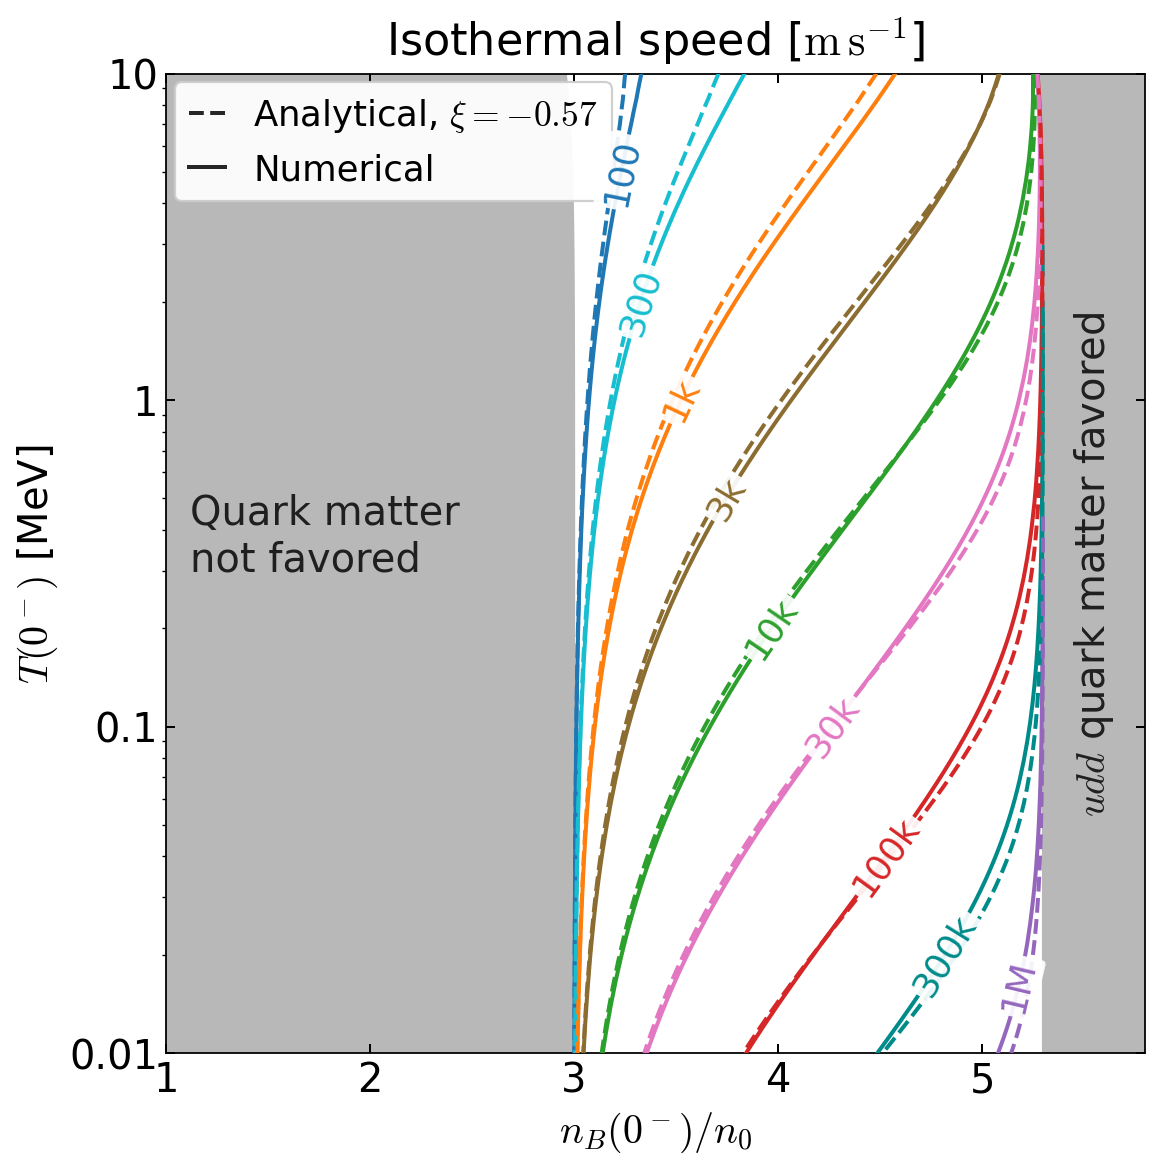

In [8]:
# Tunable plotting parameters
CONTOUR_LEVELS = (100.0, 300.0, 1000.0, 3000.0, 10000.0, 30000.0, 100000.0, 300000.0, 1000000.0)
CONTOUR_COLORS = ('#1f77b4', '#17becf', '#ff7f0e', '#8c6d31', '#2ca02c', '#e377c2', '#d62728', '#008b8b', '#9467bd')
FIGURE_SIZE = (7.2, 7.2)
FIGURE_DPI = 160
EXPORT_DPI = 220
CONSTRAINED_LAYOUT = True
BACKGROUND_COLOR = 'white'
FONT_FAMILY = 'DejaVu Sans'
MATH_FONT_SET = 'cm'
USE_TEX = False
BOX_ASPECT = 1.0
X_LIMITS = (1.0, 5.8)
Y_LIMITS = (0.01, 10.0)
X_SCALE = 'linear'
Y_SCALE = 'log'
X_TICKS = (1.0, 2.0, 3.0, 4.0, 5.0)
Y_TICKS = (0.01, 0.1, 1.0, 10.0)
Y_TICK_LABELS = ('0.01', '0.1', '1', '10')
TITLE = 'Isothermal speed [$\\mathrm{m\\,s^{-1}}$]'
TITLE_FONT_SIZE = 20
TITLE_PAD = 8
X_LABEL = '$n_B(0^-)/n_0$'
Y_LABEL = '$T(0^-)$ [MeV]'
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 18
TICK_DIRECTION = 'in'
TICKS_TOP = True
TICKS_RIGHT = True
TICK_LENGTH = 4
TICK_WIDTH = 0.9
SPINE_LINE_WIDTH = 0.8
ANALYTICAL_LINE_STYLE = '--'
NUMERICAL_LINE_STYLE = '-'
LINE_WIDTH = 1.8
ANALYTICAL_ZORDER = 4
NUMERICAL_ZORDER = 3
NUMERICAL_SPLIT_TEMPERATURE = 20.0
NUMERICAL_MARKER = 'o'
MARKER_SIZE = 19.0
MARKER_EDGE_COLOR = 'white'
MARKER_EDGE_WIDTH = 0.35
MARKER_ALPHA = 1.0
MARKER_ZORDER = 5
ISOLATED_ANALYTICAL_MARKER = 'x'
ISOLATED_ANALYTICAL_SIZE = 15.0
LABEL_CURVES = True
CONTOUR_LABEL_FONT_SIZE = 16
CONTOUR_LABEL_FORMAT = '%g'
CONTOUR_LABEL_INLINE = True
CONTOUR_LABEL_INLINE_SPACING = 4
CONTOUR_LABEL_BACKGROUND_COLOR = 'white'
CONTOUR_LABEL_BACKGROUND_ALPHA = 0.92
CONTOUR_LABEL_BACKGROUND_PAD = 0.12
CONTOUR_LABEL_BACKGROUND_STYLE = 'round'
CONTOUR_LABEL_EDGE_COLOR = 'none'
CONTOUR_LABEL_ZORDER = 6
LABEL_TEMPERATURES = {100.0: 5.0, 300.0: 2.0, 1000.0: 1.0, 3000.0: 0.5, 10000.0: 0.2, 30000.0: 0.1, 100000.0: 0.04, 300000.0: 0.02, 1000000.0: 0.016}
EXCLUDED_REGION_COLOR = '0.72'
EXCLUDED_REGION_ALPHA = 1.0
EXCLUDED_REGION_ZORDER = 0
INNER_REGION_TEXT = 'Quark matter\nnot favored'
INNER_REGION_POSITION = (1.12, 0.3)
OUTER_REGION_TEXT = '$udd$ quark matter favored'
OUTER_REGION_POSITION = (5.55, 0.316)
OUTER_REGION_ROTATION = 90
OUTER_REGION_ALIGNMENT = 'center'
OUTER_REGION_VERTICAL_ALIGNMENT = 'center'
REGION_TEXT_COLOR = '0.12'
REGION_TEXT_FONT_SIZE = 18
REGION_TEXT_ZORDER = 6
LEGEND_LOCATION = 'upper left'
LEGEND_FONT_SIZE = 16
LEGEND_HANDLE_LENGTH = 1.0
LEGEND_BORDER_AXES_PAD = 0.25
LEGEND_FRAME_ALPHA = 0.94
LEGEND_FACE_COLOR = 'white'
LEGEND_EDGE_COLOR = '0.8'
LEGEND_HANDLE_COLOR = '0.15'
LEGEND_MARKER_SIZE = 5.0
SHOW_METHOD_LEGEND = True
SHOW_SPEED_LEGEND = False
SPEED_LEGEND_LOCATION = 'lower left'
SPEED_LEGEND_TITLE = '$u(0^-)$ [m s$^{-1}$]'
SPEED_LEGEND_FONT_SIZE = 16
SPEED_LEGEND_COLUMNS = 2
SPEED_LEGEND_ANCHOR = (0.005, 0.005)
SPEED_LEGEND_HANDLE_LENGTH = 1.3
SPEED_LEGEND_COLUMN_SPACING = 0.7
SPEED_LEGEND_HANDLE_TEXT_PAD = 0.4
SPEED_LEGEND_LABEL_SPACING = 0.3
SPEED_LABELS = ('100', '300', '1k', '3k', '10k', '30k', '100k', '300k', '1M')
SHOW_GRID = False
EXPORT_STEM = 'isothermal-lowT-logT-xi-fit'
XI = XI_LOW_T_FIT   # contour fit on the row mesh
LOW_T_UPSAMPLE = 8    # display-only PCHIP refinement along rows in logit(f)
OUTPUT_DIRECTORY = "local_analysis_results/26-10-27"

log_style = dict(iso_plot.LOG_REFERENCE_STYLE)
log_style.update({key.lower(): value for key, value in list(globals().items())
                  if key.isupper() and key.lower() in log_style})
analytic_lowT_retuned = dict(analytic_lowT, speed_m_s=iso_xi.retune(xi_cache_lowT, XI))
lines = {}
for name, payload in (("numerical", numerical_lowT), ("analytic", analytic_lowT_retuned)):
    x, T, logv = iso_plot.contour_arrays(payload, LOW_T_UPSAMPLE, "logit")
    lines[name] = iso_plot.contour_lines(x, T, logv, CONTOUR_LEVELS, log_T=True)

with plt.rc_context({"font.family": FONT_FAMILY, "mathtext.fontset": MATH_FONT_SET, "text.usetex": USE_TEX}):
    figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI, constrained_layout=CONSTRAINED_LAYOUT,
                                facecolor=BACKGROUND_COLOR)
    axis.set_facecolor(BACKGROUND_COLOR)
    iso_plot.draw_log_reference(axis, boundary_curves, lines["numerical"], lines["analytic"], XI, log_style)
    for extension in ("png", "pdf"):
        figure.savefig(ROOT / OUTPUT_DIRECTORY / f"{EXPORT_STEM}.{extension}", dpi=EXPORT_DPI,
                       facecolor=BACKGROUND_COLOR)
    plt.show()

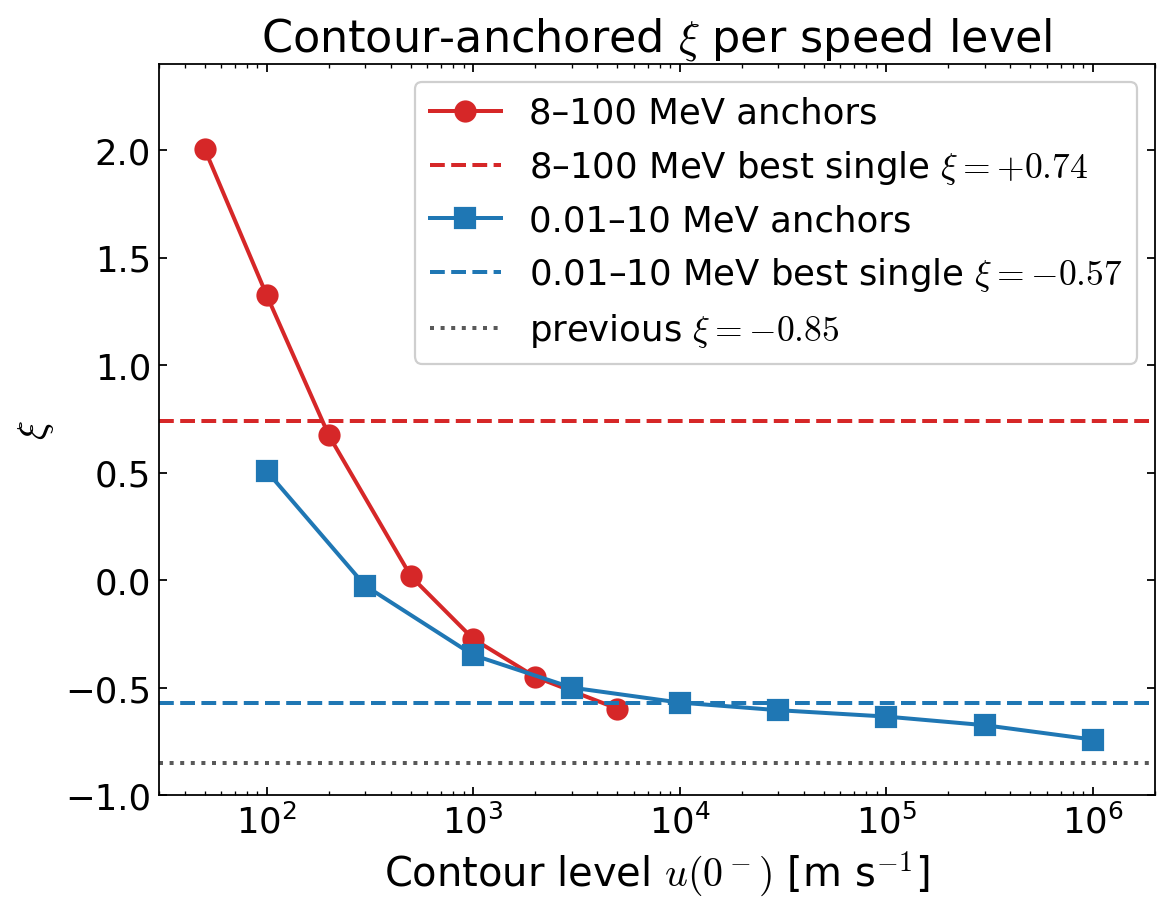

In [9]:
# Tunable plotting parameters
FIGURE_SIZE = (7.2, 5.6)
FIGURE_DPI = 160
EXPORT_DPI = 220
BACKGROUND_COLOR = 'white'
MATH_FONT_SET = 'cm'
HIGH_T_COLOR = '#d62728'
LOW_T_COLOR = '#1f77b4'
REFERENCE_COLOR = '0.35'
HIGH_T_MARKER = 'o'
LOW_T_MARKER = 's'
MARKER_SIZE = 9
LINE_WIDTH = 1.8
FIT_LINE_STYLE = '--'
REFERENCE_LINE_STYLE = ':'
X_SCALE = 'log'
X_LIMITS = (30.0, 2.0e6)
Y_LIMITS = (-1.0, 2.4)
TITLE = r'Contour-anchored $\xi$ per speed level'
TITLE_FONT_SIZE = 20
X_LABEL = r'Contour level $u(0^-)$ [m s$^{-1}$]'
Y_LABEL = r'$\xi$'
AXIS_LABEL_FONT_SIZE = 18
TICK_LABEL_FONT_SIZE = 16
LEGEND_FONT_SIZE = 16
LEGEND_LOCATION = 'upper right'
TICK_DIRECTION = 'in'
EXPORT_STEM = 'local_analysis_results/26-10-27/isothermal-xi-anchors'

with plt.rc_context({"mathtext.fontset": MATH_FONT_SET}):
    figure, axis = plt.subplots(figsize=FIGURE_SIZE, dpi=FIGURE_DPI, constrained_layout=True,
                                facecolor=BACKGROUND_COLOR)
    for tag, label, color, marker, fit in (("highT", "8–100 MeV", HIGH_T_COLOR, HIGH_T_MARKER, XI_HIGH_T_FIT),
                                           ("lowT", "0.01–10 MeV", LOW_T_COLOR, LOW_T_MARKER, XI_LOW_T_FIT)):
        anchors = xi_fit["level_anchors"][tag]
        axis.plot([float(k) for k in anchors], [v["xi"] for v in anchors.values()], marker=marker,
                  color=color, linewidth=LINE_WIDTH, markersize=MARKER_SIZE, label=f"{label} anchors")
        axis.axhline(fit, color=color, linestyle=FIT_LINE_STYLE, linewidth=LINE_WIDTH,
                     label=rf"{label} best single $\xi={fit:+g}$")
    axis.axhline(iso_common.XI, color=REFERENCE_COLOR, linestyle=REFERENCE_LINE_STYLE, linewidth=LINE_WIDTH,
                 label=rf"previous $\xi={iso_common.XI:g}$")
    axis.set(xscale=X_SCALE, xlim=X_LIMITS, ylim=Y_LIMITS)
    axis.set_title(TITLE, fontsize=TITLE_FONT_SIZE)
    axis.set_xlabel(X_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.set_ylabel(Y_LABEL, fontsize=AXIS_LABEL_FONT_SIZE)
    axis.tick_params(which="both", direction=TICK_DIRECTION, top=True, right=True, labelsize=TICK_LABEL_FONT_SIZE)
    axis.legend(fontsize=LEGEND_FONT_SIZE, loc=LEGEND_LOCATION, framealpha=0.94)
    for extension in ("png", "pdf"):
        figure.savefig(ROOT / f"{EXPORT_STEM}.{extension}", dpi=EXPORT_DPI, facecolor=BACKGROUND_COLOR)
    plt.show()